In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the raw dataset

file_path = "data/raw/retail_store_sales.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()
df.tail()
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column Names:")
print(df.columns.tolist())
df.info()
df.describe(include="all").T

Number of rows: 12575
Number of columns: 11
Column Names:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']
<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.1+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction ID,12575,12575,TXN_6867343,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,12575,25,CUST_05,544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,12575,8,Furniture,1591,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item,11362,200,Item_2_BEV,126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price Per Unit,11966.0,NaN,NaN,NaN,23.365912,10.743519,5.0,14.0,23.0,33.5,41.0
Quantity,11971.0,NaN,NaN,NaN,5.53638,2.857883,1.0,3.0,6.0,8.0,10.0
Total Spent,11971.0,NaN,NaN,NaN,129.652577,94.750697,5.0,51.0,108.5,192.0,410.0
Payment Method,12575,3,Cash,4310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,12575,2,Online,6354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction Date,12575,1114,2022-05-30,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Create initial data quality report

quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2),
    "Unique Values": df.nunique(),
})

print("Initial Data Quality Report")

display(quality_report)

Initial Data Quality Report


,Data Type,Missing Values,Missing Percentage,Unique Values
Transaction ID,str,0,0.00,12575
Customer ID,str,0,0.00,25
Category,str,0,0.00,8
Item,str,1213,9.65,200
Price Per Unit,float64,609,4.84,25
Quantity,float64,604,4.80,10
Total Spent,float64,604,4.80,227
Payment Method,str,0,0.00,3
Location,str,0,0.00,2
Transaction Date,str,0,0.00,1114


In [5]:
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

Total duplicate rows: 0


In [6]:
quality_report.to_csv(
    "outputs/initial_data_quality_report.csv"
)

print("Initial quality report saved successfully!")

Initial quality report saved successfully!


## Detailed Data Investigation

In this section, we inspect categorical and numerical columns to identify inconsistent formatting, unexpected values, and possible data quality issues before cleaning.

In [7]:
# Inspect unique categorical values

categorical_columns = [
    "Category",
    "Payment Method",
    "Location",
    "Discount Applied"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))


--- Category ---
Category
Furniture                             1591
Electric household essentials         1591
Food                                  1588
Milk Products                         1584
Butchers                              1568
Beverages                             1567
Computers and electric accessories    1558
Patisserie                            1528
Name: count, dtype: int64

--- Payment Method ---
Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64

--- Location ---
Location
Online      6354
In-store    6221
Name: count, dtype: int64

--- Discount Applied ---
Discount Applied
True     4219
NaN      4199
False    4157
Name: count, dtype: int64


In [8]:
# Numerical data investigation

numeric_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

for column in numeric_columns:
    print(f"\n--- {column} ---")
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())
    print("Negative values:", (df[column] < 0).sum())
    print("Zero values:", (df[column] == 0).sum())


--- Price Per Unit ---
Minimum: 5.0
Maximum: 41.0
Negative values: 0
Zero values: 0

--- Quantity ---
Minimum: 1.0
Maximum: 10.0
Negative values: 0
Zero values: 0

--- Total Spent ---
Minimum: 5.0
Maximum: 410.0
Negative values: 0
Zero values: 0


In [9]:
# Test date conversion without modifying original data

parsed_dates = pd.to_datetime(
    df["Transaction Date"],
    errors="coerce"
)

print("Invalid dates:", parsed_dates.isna().sum())
print("Earliest date:", parsed_dates.min())
print("Latest date:", parsed_dates.max())

Invalid dates: 0
Earliest date: 2022-01-01 00:00:00
Latest date: 2025-01-18 00:00:00


In [10]:
# Check transaction amount consistency

expected_total = (
    df["Price Per Unit"] * df["Quantity"]
)

difference = (
    df["Total Spent"] - expected_total
).abs()

valid_rows = (
    df["Total Spent"].notna()
    & expected_total.notna()
)

print(
    "Rows with inconsistent totals:",
    (difference[valid_rows] > 0.01).sum()
)

print(
    "Rows checked:",
    valid_rows.sum()
)

Rows with inconsistent totals: 0
Rows checked: 11362


In [11]:
# IQR-based outlier investigation

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound)
        | (df[column] > upper_bound)
    ]

    print(f"\n--- {column} ---")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Potential Outliers:", len(outliers))


--- Price Per Unit ---
Lower Bound: -15.25
Upper Bound: 62.75
Potential Outliers: 0

--- Quantity ---
Lower Bound: -4.5
Upper Bound: 15.5
Potential Outliers: 0

--- Total Spent ---
Lower Bound: -160.5
Upper Bound: 403.5
Potential Outliers: 60


## Missing Data Investigation

Missing values can affect the reliability of analysis. Before handling them, we examine their distribution and relationships to determine the most appropriate treatment for each column.

No missing values will be replaced without first investigating their patterns.

In [12]:
# Count missing values in every column

missing_counts = df.isnull().sum()

print("Missing values by column:")
display(missing_counts[missing_counts > 0])

Missing values by column:


Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Discount Applied    4199
dtype: int64

In [13]:
# Identify patterns of missing values

missing_patterns = (
    df.isnull()
    .value_counts()
    .reset_index(name="Number of Rows")
)

display(missing_patterns)


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Number of Rows
0,False,False,False,False,False,False,False,False,False,False,False,7579
1,False,False,False,False,False,False,False,False,False,False,True,3783
2,False,False,False,True,True,False,False,False,False,False,False,404
3,False,False,False,True,False,True,True,False,False,False,False,393
4,False,False,False,True,False,True,True,False,False,False,True,211
5,False,False,False,True,True,False,False,False,False,False,True,205


In [14]:
# Display records where Item is missing

missing_items = df[df["Item"].isnull()]

print("Rows with missing Item:", len(missing_items))

display(missing_items.head(15))

Rows with missing Item: 1213


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,NaN
17,TXN_9634894,CUST_15,Milk Products,NaN,NaN,10.0,275.0,Digital Wallet,Online,2022-04-17,NaN
19,TXN_4206593,CUST_01,Furniture,NaN,35.0,NaN,NaN,Digital Wallet,Online,2025-01-13,False
21,TXN_8685338,CUST_15,Milk Products,NaN,NaN,3.0,105.0,Credit Card,In-store,2023-10-29,NaN
25,TXN_3481599,CUST_05,Furniture,NaN,39.5,NaN,NaN,Cash,Online,2022-09-08,False
32,TXN_1543244,CUST_20,Food,NaN,NaN,8.0,196.0,Credit Card,Online,2024-10-25,True
34,TXN_1621497,CUST_06,Patisserie,NaN,23.0,NaN,NaN,Cash,In-store,2023-02-18,NaN


In [15]:
# Display records with missing numerical information

missing_numeric = df[
    df[["Price Per Unit", "Quantity", "Total Spent"]]
    .isnull()
    .any(axis=1)
]

print("Rows with missing numerical information:", len(missing_numeric))

display(missing_numeric.head(15))

Rows with missing numerical information: 1213


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,NaN
17,TXN_9634894,CUST_15,Milk Products,NaN,NaN,10.0,275.0,Digital Wallet,Online,2022-04-17,NaN
19,TXN_4206593,CUST_01,Furniture,NaN,35.0,NaN,NaN,Digital Wallet,Online,2025-01-13,False
21,TXN_8685338,CUST_15,Milk Products,NaN,NaN,3.0,105.0,Credit Card,In-store,2023-10-29,NaN
25,TXN_3481599,CUST_05,Furniture,NaN,39.5,NaN,NaN,Cash,Online,2022-09-08,False
32,TXN_1543244,CUST_20,Food,NaN,NaN,8.0,196.0,Credit Card,Online,2024-10-25,True
34,TXN_1621497,CUST_06,Patisserie,NaN,23.0,NaN,NaN,Cash,In-store,2023-02-18,NaN


In [16]:
# Check discount values against transaction information

discount_analysis = df.groupby(
    "Discount Applied",
    dropna=False
).agg(
    Transaction_Count=("Transaction ID", "count"),
    Average_Total_Spent=("Total Spent", "mean"),
    Average_Quantity=("Quantity", "mean")
)

display(discount_analysis)

,Transaction_Count,Average_Total_Spent,Average_Quantity
Discount Applied,,,
False,4157,129.953330,5.580979
True,4219,130.491043,5.533466
NaN,4199,128.508651,5.494985


##  Missing Data Handling

In this section, missing values will be investigated and handled using suitable strategies.

The original raw dataset will remain unchanged. All cleaning operations will be performed on a separate working copy.

In [17]:
# Create a working copy

df_clean = df.copy()

print("Working copy created successfully!")
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Working copy created successfully!
Original dataset shape: (12575, 11)
Working dataset shape: (12575, 11)


In [18]:
# Missing value summary

missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

display(missing_summary[missing_summary["Missing Count"] > 0])

,Missing Count,Missing Percentage
Item,1213,9.65
Price Per Unit,609,4.84
Quantity,604,4.80
Total Spent,604,4.80
Discount Applied,4199,33.39


In [19]:
# Check how many rows have multiple missing fields

missing_combinations = (
    df_clean.isnull()
    .astype(int)
    .value_counts()
    .reset_index(name="Row Count")
)

display(missing_combinations)

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Row Count
0,0,0,0,0,0,0,0,0,0,0,0,7579
1,0,0,0,0,0,0,0,0,0,0,1,3783
2,0,0,0,1,1,0,0,0,0,0,0,404
3,0,0,0,1,0,1,1,0,0,0,0,393
4,0,0,0,1,0,1,1,0,0,0,1,211
5,0,0,0,1,1,0,0,0,0,0,1,205


In [20]:
# Check whether numerical fields are missing together

numeric_missing_check = df_clean[
    ["Price Per Unit", "Quantity", "Total Spent"]
].isnull()

display(numeric_missing_check.sum())

print(
    "All three numerical fields missing together:",
    numeric_missing_check.all(axis=1).sum()
)

print(
    "Any numerical field missing:",
    numeric_missing_check.any(axis=1).sum()
)

Price Per Unit    609
Quantity          604
Total Spent       604
dtype: int64

All three numerical fields missing together: 0
Any numerical field missing: 1213


In [21]:
# Identify records where Total Spent is missing
# but Price Per Unit and Quantity are available

can_calculate_total = (
    df_clean["Total Spent"].isnull()
    & df_clean["Price Per Unit"].notnull()
    & df_clean["Quantity"].notnull()
)

print(
    "Missing totals that can be calculated:",
    can_calculate_total.sum()
)

Missing totals that can be calculated: 0


In [22]:
# Compare records with missing and available discounts

df_clean["Discount Status"] = np.where(
    df_clean["Discount Applied"].isnull(),
    "Missing",
    "Available"
)

display(
    df_clean.groupby("Discount Status").agg(
        Transactions=("Transaction ID", "count"),
        Average_Spending=("Total Spent", "mean"),
        Average_Quantity=("Quantity", "mean")
    )
)

,Transactions,Average_Spending,Average_Quantity
Discount Status,,,
Available,8376,130.224039,5.557059
Missing,4199,128.508651,5.494985



## Missing Value Treatment: Decisions and Justifications

1. Item:
   Missing values will be replaced with "Unknown" because the actual product identity cannot be reliably determined.

2. Price Per Unit:
   Missing values will be replaced using the median because it is a numerical variable and median imputation is less sensitive to extreme values.

3. Quantity:
   Missing values will be replaced using the median to preserve transaction records.

4. Total Spent:
   Missing values will be replaced using the median because the missing totals cannot be reconstructed from the available price and quantity values.

5. Discount Applied:
   Missing values will be retained as unknown because there is insufficient evidence to conclude that missing discounts represent False.

The original raw dataset is preserved, and all modifications are performed on the working copy.


In [23]:
#  Fill missing Item values

df_clean["Item"] = df_clean["Item"].fillna("Unknown")


# Calculate medians from original available values

price_median = df_clean["Price Per Unit"].median()
quantity_median = df_clean["Quantity"].median()
total_median = df_clean["Total Spent"].median()


# Impute missing numerical values

df_clean["Price Per Unit"] = (
    df_clean["Price Per Unit"].fillna(price_median)
)

df_clean["Quantity"] = (
    df_clean["Quantity"].fillna(quantity_median)
)

df_clean["Total Spent"] = (
    df_clean["Total Spent"].fillna(total_median)
)


# Remove temporary investigation column

if "Discount Status" in df_clean.columns:
    df_clean.drop(columns=["Discount Status"], inplace=True)


print("Missing-value treatment completed!")


Missing-value treatment completed!


C:\Users\ACER\AppData\Local\Temp\ipykernel_5768\2600883663.py:31: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.drop(columns=["Discount Status"], inplace=True)


In [24]:
# Check remaining missing values

remaining_missing = df_clean.isnull().sum()

display(
    remaining_missing[remaining_missing > 0]
)

print("\nTotal remaining missing values:",
      df_clean.isnull().sum().sum())

Discount Applied    4199
dtype: int64


Total remaining missing values: 4199



## Duplicate Removal and Data Standardisation

In this section, duplicate records will be identified and removed. Text columns will be standardised to ensure consistent formatting, and columns will be converted to appropriate data types.


In [25]:
# Check duplicate records

duplicates_before = df_clean.duplicated().sum()

print("Duplicate rows before cleaning:", duplicates_before)

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

duplicates_after = df_clean.duplicated().sum()

print("Duplicate rows after cleaning:", duplicates_after)

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0


In [26]:
# Standardise text formatting

text_columns = [
    "Transaction ID",
    "Customer ID",
    "Category",
    "Item",
    "Payment Method",
    "Location"
]

for column in text_columns:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
    )

print("Text formatting standardised!")

Text formatting standardised!


In [27]:
# Standardise categorical formatting

df_clean["Category"] = (
    df_clean["Category"].str.title()
)

df_clean["Payment Method"] = (
    df_clean["Payment Method"].str.title()
)

df_clean["Location"] = (
    df_clean["Location"].str.title()
)

print("Categorical values standardised!")

Categorical values standardised!


In [28]:
# Convert Transaction Date to datetime

df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Transaction Date"],
    errors="coerce"
)

# Convert numeric columns

df_clean["Price Per Unit"] = pd.to_numeric(
    df_clean["Price Per Unit"],
    errors="coerce"
)

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"],
    errors="coerce"
)

df_clean["Total Spent"] = pd.to_numeric(
    df_clean["Total Spent"],
    errors="coerce"
)

# Keep ID columns as strings

df_clean["Transaction ID"] = df_clean["Transaction ID"].astype("string")
df_clean["Customer ID"] = df_clean["Customer ID"].astype("string")

print("Data type conversion completed!")

Data type conversion completed!


In [29]:
# Convert Discount Applied to nullable Boolean

df_clean["Discount Applied"] = (
    df_clean["Discount Applied"].astype("boolean")
)

print(df_clean["Discount Applied"].value_counts(dropna=False))

Discount Applied
True     4219
<NA>     4199
False    4157
Name: count, dtype: Int64


In [30]:
# Display updated data types

print(df_clean.dtypes)

print("\nDataset shape:", df_clean.shape)

Transaction ID              string
Customer ID                 string
Category                    string
Item                        string
Price Per Unit             float64
Quantity                   float64
Total Spent                float64
Payment Method              string
Location                    string
Transaction Date    datetime64[us]
Discount Applied           boolean
dtype: object

Dataset shape: (12575, 11)


## Outlier Detection and Treatment

Outliers are identified using the Interquartile Range (IQR) method.
Potential outliers are investigated before deciding whether to remove,
retain, or transform them.

Extreme values that represent valid retail transactions will be retained.

In [33]:
numeric_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

outlier_summary = []

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_report = pd.DataFrame(outlier_summary)

display(outlier_report)

,Column,Lower Bound,Upper Bound,Outlier Count
0,Price Per Unit,-15.25,62.75,0
1,Quantity,-4.50,15.50,0
2,Total Spent,-160.50,403.50,60


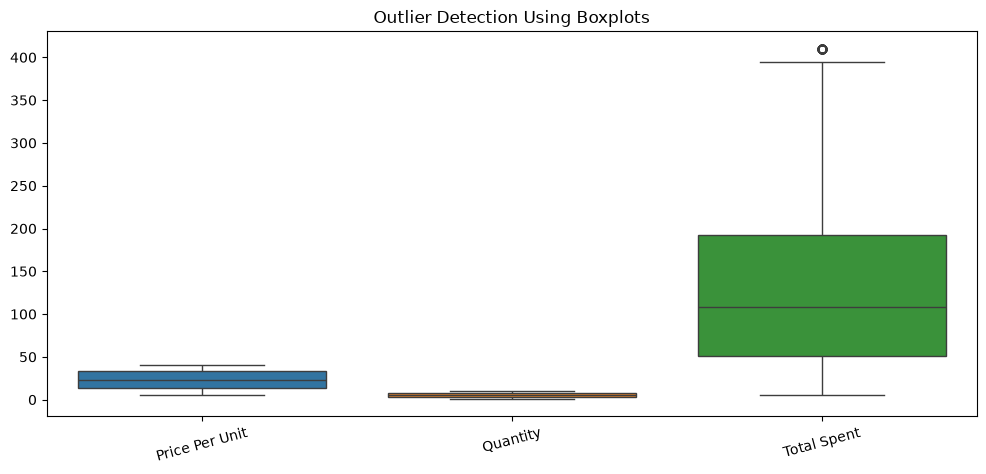

In [34]:
plt.figure(figsize=(12, 5))

sns.boxplot(data=df[numeric_columns])

plt.title("Outlier Detection Using Boxplots")
plt.xticks(rotation=15)
plt.show()

In [35]:
Q1 = df["Total Spent"].quantile(0.25)
Q3 = df["Total Spent"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

high_transactions = df[
    df["Total Spent"] > upper_bound
]

display(
    high_transactions[
        ["Transaction ID", "Category", "Item",
         "Price Per Unit", "Quantity", "Total Spent"]
    ].head(10)
)

,Transaction ID,Category,Item,Price Per Unit,Quantity,Total Spent
27,TXN_1599706,Furniture,Item_25_FUR,41.0,10.0,410.0
133,TXN_2953434,Furniture,Item_25_FUR,41.0,10.0,410.0
339,TXN_4374445,Food,Item_25_FOOD,41.0,10.0,410.0
869,TXN_1814138,Beverages,Item_25_BEV,41.0,10.0,410.0
1060,TXN_3710081,Furniture,Item_25_FUR,41.0,10.0,410.0
1088,TXN_1273334,Beverages,Item_25_BEV,41.0,10.0,410.0
1468,TXN_1938135,Butchers,Item_25_BUT,41.0,10.0,410.0
1505,TXN_8520397,Electric household essentials,Item_25_EHE,41.0,10.0,410.0
1568,TXN_8048041,Butchers,Item_25_BUT,41.0,10.0,410.0
1950,TXN_1860120,Furniture,Item_25_FUR,41.0,10.0,410.0


##  Before-and-After Data Quality Report

The original and cleaned datasets are compared to evaluate the
effectiveness of the data cleaning process.

The comparison includes dataset dimensions, missing values,
duplicate records, and data types.

Unknown discount values are intentionally retained as missing
because their actual status cannot be determined.

In [36]:
comparison_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Total Missing Values",
        "Missing Item Values",
        "Missing Price Per Unit",
        "Missing Quantity",
        "Missing Total Spent",
        "Missing Discount Applied"
    ],
    "Before Cleaning": [
        len(df),
        len(df.columns),
        df.duplicated().sum(),
        df.isnull().sum().sum(),
        df["Item"].isnull().sum(),
        df["Price Per Unit"].isnull().sum(),
        df["Quantity"].isnull().sum(),
        df["Total Spent"].isnull().sum(),
        df["Discount Applied"].isnull().sum()
    ],
    "After Cleaning": [
        len(df_clean),
        len(df_clean.columns),
        df_clean.duplicated().sum(),
        df_clean.isnull().sum().sum(),
        df_clean["Item"].isnull().sum(),
        df_clean["Price Per Unit"].isnull().sum(),
        df_clean["Quantity"].isnull().sum(),
        df_clean["Total Spent"].isnull().sum(),
        df_clean["Discount Applied"].isnull().sum()
    ]
})

display(comparison_report)

,Metric,Before Cleaning,After Cleaning
0,Total Rows,12575,12575
1,Total Columns,11,11
2,Duplicate Rows,0,0
3,Total Missing Values,7229,4199
4,Missing Item Values,1213,0
5,Missing Price Per Unit,609,0
6,Missing Quantity,604,0
7,Missing Total Spent,604,0
8,Missing Discount Applied,4199,4199


In [37]:
missing_comparison = pd.DataFrame({
    "Column": df.columns,
    "Before Cleaning": df.isnull().sum().values,
    "After Cleaning": df_clean.isnull().sum().values
})

missing_comparison["Missing Values Handled"] = (
    missing_comparison["Before Cleaning"] -
    missing_comparison["After Cleaning"]
)

display(missing_comparison)

,Column,Before Cleaning,After Cleaning,Missing Values Handled
0,Transaction ID,0,0,0
1,Customer ID,0,0,0
2,Category,0,0,0
3,Item,1213,0,1213
4,Price Per Unit,609,0,609
5,Quantity,604,0,604
6,Total Spent,604,0,604
7,Payment Method,0,0,0
8,Location,0,0,0
9,Transaction Date,0,0,0


In [38]:
comparison_report.to_csv(
    "outputs/before_after_comparison.csv",
    index=False
)

missing_comparison.to_csv(
    "outputs/missing_values_comparison.csv",
    index=False
)

print("Quality reports saved successfully!")

Quality reports saved successfully!


##  Export Cleaned Dataset

The cleaned dataset is exported as a CSV file for future analysis,
reporting, and dashboard development.

In [39]:
output_path = "data/cleaned/retail_store_sales_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset exported successfully!")
print("File location:", output_path)
print("Final dataset shape:", df_clean.shape)

Cleaned dataset exported successfully!
File location: data/cleaned/retail_store_sales_cleaned.csv
Final dataset shape: (12575, 11)


In [40]:
verified_df = pd.read_csv(output_path)

print("Exported dataset shape:", verified_df.shape)
print("\nMissing values:")
print(verified_df.isnull().sum())

print("\nFirst 5 records:")
display(verified_df.head())

Exported dataset shape: (12575, 11)

Missing values:
Transaction ID         0
Customer ID            0
Category               0
Item                   0
Price Per Unit         0
Quantity               0
Total Spent            0
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

First 5 records:


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False
